# CLC02 – Nhóm 4 · PERSUADE: giá trị thêm của cấu trúc lập luận (RQ1) và mất mát khi dự đoán vai trò (RQ2)

Notebook này gộp toàn bộ source (`src/*.py`) thành **một file**, đồng thời thực hiện các điểm thầy yêu cầu sửa trong *Nhan_xet_Week8*:

| # | Nhận xét của thầy | Phần trong notebook |
|---|---|---|
| 1 | M1 chưa loại hết lợi thế độ dài → cần đối chứng nhóm đặc trưng độ dài cùng thuật toán, thử bỏ `n_chars` & proxy; dùng importance đúng cách; test nhân đôi văn bản phải dùng dự đoán ngoài mẫu | §3, §6, §8 |
| 2 | M3 cần sơ đồ fit (outer/inner prompt) kiểm bằng ID + nói rõ thông tin gold còn lại (ranh giới đoạn) | §2, §4 (có kiểm tra leak bằng assert + biến thể *chỉ ranh giới*) |
| 3 | Bảng số/CI phải khớp câu hỏi: một nguồn số duy nhất, ddof thống nhất, số bài từng fold, tách QWK gộp vs mean theo đề, paired Δ từng đề | §5, §6 |
| 4 | Step 3 là lõi; Step 2 / feedback prioritisation chỉ là hướng sau | §0, §10 |
| – | Ba bài cấu trúc giúp, ba bài cấu trúc hại | §9 |

> **Quy ước thống nhất cho toàn notebook** (để không lặp lại lỗi lệch số ở Bảng 2/3):
> * Mọi con số trong bảng lấy từ **cùng một** dictionary dự đoán `PRED` (trung bình dự đoán liên tục của các seed, rồi mới làm tròn về 1–6).
> * **Chỉ số chính = QWK trung bình theo đề (8 đề, held-out)** vì câu hỏi là *đề mới*; QWK gộp (pooled) chỉ là chỉ số phụ.
> * Độ lệch chuẩn luôn dùng `ddof=1` trên 8 đề. Δ luôn là *paired* theo từng đề.
> * Phạm vi: chỉ 8 đề *Independent* / 7 869 bài. Không có thêm kiểm chứng "đề chưa thấy" từ test chính thức (cùng đề với train).

## §0. Việc cần làm tiếp (ngoài code) – checklist mang đến buổi gặp

- [ ] **Sơ đồ outer/inner prompt của M3** với ID cụ thể → §2 in bảng + assert; chụp bảng này đưa vào báo cáo.
- [ ] **Bảng M0 mở rộng / M1 / M2 / M3** cùng thuật toán, từng đề, nhiều seed, dự đoán ngoài mẫu → §5–§6.
- [ ] **Ba bài cấu trúc giúp, ba bài hại** → §9 (điền phần diễn giải bằng lời của nhóm).
- [ ] **Sửa Bảng 1**: "Nhóm 6 dùng VNU" là nhầm – CLC02 nhóm 6 đang dùng **PERSUADE**. Xác nhận lại với nhóm 6 và ghi ranh giới phần việc trước buổi gặp.
- [ ] **Sửa danh mục nguồn**:
  * ArguLens: Wang, Shi, Tang & Qin (có thật) – dùng để phân biệt *oracle discourse features* với *end-to-end* → định vị M2 (oracle/gold) và M3 (predicted roles, gold boundary). **Không** so QWK khác protocol như cùng benchmark.
  * Chen/Wu/Zhang, *Assessing fairness in AI-assisted writing scoring: Developing fairness measures to detect predictive bias in automated essay scoring*, **Assessing Writing**, 2026, DOI 10.1016/j.asw.2026.101066 – đọc nguồn rồi trích, không ghi "không tìm thấy".
  * Giữ Yang et al. 2024 để giải thích so sánh cross-prompt.
- [ ] Đổi tiêu đề/đầu ra cho khớp: **Step 3 (chấm điểm bài luận) là lõi**; "feedback prioritisation" chỉ là hướng phát triển, vì Step 2 (Ineffective recall 0,19 / F1 0,07) chưa đủ làm cờ cho giáo viên và κ = 0,32 là *một* giới hạn của nhãn chứ không tự giải thích hết lỗi mô hình.
- [ ] ELL fairness và Step 2: **không mở rộng** vòng này.

## §1. Cấu hình & dữ liệu

In [1]:
import os, json, re, warnings, time
from pathlib import Path
import numpy as np, pandas as pd, scipy.sparse as sp
import matplotlib.pyplot as plt
from scipy.stats import binomtest
from joblib import Parallel, delayed
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.feature_extraction.text import HashingVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import cohen_kappa_score, f1_score, classification_report
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 50)

# ---- cấu hình ---------------------------------------------------------------------------
ROOT = Path.cwd()                       # chạy notebook trong thư mục AFP_Project
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
PROC, RES, FIGS = ROOT / "data" / "processed", ROOT / "results", ROOT / "figs"
RAW_TRAIN = ROOT / "data" / "raw" / "persuade_corpus_2.0_train.csv"
for d in (PROC, RES, FIGS): d.mkdir(parents=True, exist_ok=True)

SEEDS = [0, 1, 2]        # GB: 3 seed (subsample=0.8 nên seed có ảnh hưởng)
N_JOBS = max(1, (os.cpu_count() or 2) - 2)
SAMPLE_DUP = 40          # số bài / đề cho test nhân đôi văn bản
print("ROOT:", ROOT, "| n_jobs:", N_JOBS)

ROOT: D:\Hoa\năm 4\MLA\AFP_Project | n_jobs: 14


In [2]:
# ---- metric -----------------------------------------------------------------------------
def to_level(x):
    return np.clip(np.rint(x), 1, 6).astype(int)

def qwk(y, yp):
    """QWK nhanh trên thang 1-6 (đã kiểm tra bằng sklearn ở ô dưới)."""
    y, yp = np.asarray(y, int), np.asarray(yp, int)
    O = np.bincount((y - 1) * 6 + (yp - 1), minlength=36).reshape(6, 6).astype(float)
    i, j = np.indices((6, 6)); W = (i - j) ** 2 / 25.0
    E = np.outer(O.sum(1), O.sum(0)) / O.sum()
    return 1.0 - (W * O).sum() / (W * E).sum()

_r = np.random.default_rng(0); _a = _r.integers(1, 7, 500); _b = np.clip(_a + _r.integers(-1, 2, 500), 1, 6)
assert abs(qwk(_a, _b) - cohen_kappa_score(_a, _b, weights="quadratic", labels=[1,2,3,4,5,6])) < 1e-9
print("qwk() khớp sklearn")

qwk() khớp sklearn


In [3]:
# ---- dữ liệu: ưu tiên bản đã xử lý, nếu chưa có thì dựng từ CSV gốc (= 01_prepare_data.py) -------
if (PROC / "essays.pkl").exists() and (PROC / "segments.pkl").exists():
    essays = pd.read_pickle(PROC / "essays.pkl"); segs = pd.read_pickle(PROC / "segments.pkl")
else:
    COLS_SEG = ["essay_id_comp","prompt_name","task","discourse_id","discourse_start","discourse_end",
                "discourse_text","discourse_type","discourse_effectiveness"]
    COLS_ESSAY = ["essay_id_comp","full_text","holistic_essay_score","prompt_name","task",
                  "ell_status","grade_level","gender","essay_word_count"]
    raw = pd.read_csv(RAW_TRAIN)
    essays = raw[COLS_ESSAY].drop_duplicates("essay_id_comp").reset_index(drop=True)
    essays["ell"] = essays["ell_status"].map({"Yes": 1, "No": 0})
    segs = raw[COLS_SEG].dropna(subset=["discourse_text"]).reset_index(drop=True)
    segs["seg_len"] = segs["discourse_text"].str.split().str.len()
    essays.to_pickle(PROC / "essays.pkl"); segs.to_pickle(PROC / "segments.pkl")

ess = essays[essays.task == "Independent"].reset_index(drop=True)      # đề source-based bị loại
y = ess.holistic_essay_score.values.astype(int)
groups = ess.prompt_name.values
prompts = sorted(set(groups))
print(f"Independent: {len(ess)} bài | {len(prompts)} đề")
print(pd.DataFrame({"n_essays": ess.groupby("prompt_name").size(),
                    "mean_score": ess.groupby("prompt_name").holistic_essay_score.mean().round(2)}))
print("phân bố điểm:", dict(pd.Series(y).value_counts().sort_index()))

Independent: 7869 bài | 8 đề
                                       n_essays  mean_score
prompt_name                                                
Cell phones at school                       829        3.06
Community service                           768        2.90
Distance learning                          1498        4.41
Grades for extracurricular activities       815        2.93
Mandatory extracurricular activities        839        3.79
Phones and driving                          701        3.83
Seeking multiple opinions                  1544        3.84
Summer projects                             875        4.52
phân bố điểm: {1: np.int64(39), 2: np.int64(1077), 3: np.int64(2173), 4: np.int64(2565), 5: np.int64(1545), 6: np.int64(470)}


In [4]:
# ---- M1: ~45 đặc trưng ngôn ngữ (= features.py) -------------------------------------------------
WORD = re.compile(r"[A-Za-z']+")
CONNECTIVES = {
    "addition": ["also","furthermore","moreover","additionally","besides","in addition"],
    "contrast": ["however","but","although","though","while","whereas","nevertheless","on the other hand","yet"],
    "cause": ["because","since","therefore","thus","consequently","so that","as a result","due to"],
    "example": ["for example","for instance","such as","like","in fact"],
    "conclusion": ["in conclusion","to conclude","overall","in summary","finally","to sum up"],
    "sequence": ["first","second","third","next","then","lastly"],
}
HEDGES = ["maybe","perhaps","might","could","probably","possibly","may"]
FIRST_PERSON = ["i","my","me","we","our","us"]; SECOND_PERSON = ["you","your","u"]

def _syllables(w):
    w = w.lower(); n = len(re.findall(r"[aeiouy]+", w))
    if w.endswith("e") and n > 1: n -= 1
    return max(n, 1)

def _count(text_l, phrases):
    return sum(len(re.findall(r"\b" + re.escape(p) + r"\b", text_l)) for p in phrases)

def essay_features(text):
    words = WORD.findall(text); n = max(len(words), 1); lw = [w.lower() for w in words]
    sents = [s for s in re.split(r"(?<=[.!?])\s+", text.strip()) if s.strip()]; ns = max(len(sents), 1)
    paras = [p for p in re.split(r"\n\s*\n|\n", text) if p.strip()]
    sent_lens = np.array([len(WORD.findall(s)) for s in sents] or [0]); wlen = np.array([len(w) for w in words] or [0])
    syl = sum(_syllables(w) for w in words); text_l = text.lower(); uniq = len(set(lw))
    from collections import Counter
    cnt = Counter(lw)
    f = {
        "n_words": len(words), "n_chars": len(text), "n_sents": ns, "n_paras": len(paras), "log_words": np.log1p(len(words)),
        "avg_sent_len": sent_lens.mean(), "std_sent_len": sent_lens.std(), "max_sent_len": sent_lens.max(),
        "short_sent_ratio": np.mean(sent_lens < 6), "long_sent_ratio": np.mean(sent_lens > 25),
        "avg_para_len": len(words) / max(len(paras), 1),
        "avg_word_len": wlen.mean(), "long_word_ratio": np.mean(wlen >= 7),
        "n_unique": uniq, "ttr": uniq / n, "root_ttr": uniq / np.sqrt(n),
        "hapax_ratio": sum(1 for c in cnt.values() if c == 1) / n,
        "flesch": 206.835 - 1.015 * (n / ns) - 84.6 * (syl / n), "fk_grade": 0.39 * (n / ns) + 11.8 * (syl / n) - 15.59,
        "syl_per_word": syl / n,
        "n_commas": text.count(","), "commas_per_sent": text.count(",") / ns, "n_questions": text.count("?"),
        "n_exclaim": text.count("!"), "n_quotes": text.count('"'), "n_semicolon_colon": text.count(";") + text.count(":"),
        "n_apostrophe": text.count("'"), "caps_ratio": sum(c.isupper() for c in text) / max(len(text), 1),
        "lowercase_i": len(re.findall(r"\bi\b", text)), "no_end_punct": float(not text.rstrip().endswith((".","!","?",'"'))),
        "repeated_word": len(re.findall(r"\b(\w+)\s+\1\b", text_l)), "double_space": text.count("  "),
        "first_person": _count(text_l, FIRST_PERSON) / n, "second_person": _count(text_l, SECOND_PERSON) / n,
        "hedges": _count(text_l, HEDGES) / n,
    }
    for k, v in CONNECTIVES.items(): f[f"conn_{k}"] = _count(text_l, v)
    f["conn_total"] = sum(f[f"conn_{k}"] for k in CONNECTIVES); f["conn_per_sent"] = f["conn_total"] / ns
    return f

def build_feature_frame(texts):
    return pd.DataFrame(Parallel(n_jobs=N_JOBS, batch_size=64)(delayed(essay_features)(t) for t in texts))

FEAT_CACHE = PROC / "features_independent.pkl"
if FEAT_CACHE.exists() and len(pd.read_pickle(FEAT_CACHE)) == len(ess):
    X1 = pd.read_pickle(FEAT_CACHE)
else:
    X1 = build_feature_frame(ess.full_text).fillna(0); X1.to_pickle(FEAT_CACHE)
assert len(X1) == len(ess) and np.corrcoef(X1.n_words, ess.essay_word_count)[0,1] > 0.95, "feature/essay lệch hàng?"  # n_words (regex) ≈ essay_word_count (cột gốc), r≈0.98
print("M1:", X1.shape[1], "đặc trưng | r(n_words, score) =", round(np.corrcoef(X1.n_words, y)[0,1], 3),
      "| r(n_chars, score) =", round(np.corrcoef(X1.n_chars, y)[0,1], 3))

M1: 43 đặc trưng | r(n_words, score) = 0.783 | r(n_chars, score) = 0.807


## §2. Step 1 – nhận vai trò đoạn + **sơ đồ cross-fit của M3** (kiểm bằng ID)

**Thiết kế (không đổi so với bản trước, nhưng giờ có assert):** với mỗi *outer prompt* `p` (đề giữ lại để chấm điểm):

* **Feature của bài test (đề p):** bộ nhận vai trò được fit trên 7 đề còn lại (không có `p`).
* **Feature của bài train (đề q ≠ p):** bộ nhận vai trò được fit trên 6 đề *inner* = tất cả trừ `p` và `q` → bài q không bao giờ được gán nhãn bởi mô hình đã thấy nhãn vai trò của chính nó (tránh feature "quá sạch" ở train so với test) và nhãn của `p` không lọt vào đâu cả.
* Bộ nhận vai trò: LinearSVC trên hashing uni+bigram + 5 đặc trưng vị trí/độ dài đoạn.

**Giới hạn thông tin gold còn lại trong M3:** *ranh giới đoạn* (số đoạn, vị trí, độ dài đoạn, đoạn nào là "Unannotated") vẫn là gold. Vì vậy M3 chưa phải hệ thống nhận bài thô. §4 đo riêng phần lợi chỉ đến từ ranh giới.

In [5]:
seg = segs[segs.task == "Independent"].merge(ess[["essay_id_comp","full_text"]], on="essay_id_comp").reset_index(drop=True)
seg["role"] = seg.discourse_type.replace({"Unannotated": "none"})
seg["rel_pos"] = seg.discourse_start / seg.full_text.str.len()
seg["rank_in_essay"] = seg.groupby("essay_id_comp").discourse_start.rank(method="first")
seg["n_in_essay"] = seg.groupby("essay_id_comp").discourse_start.transform("count")
seg["rank_rel"] = seg.rank_in_essay / seg.n_in_essay
seg["is_first"] = (seg.rank_in_essay == 1).astype(float); seg["is_last"] = (seg.rank_in_essay == seg.n_in_essay).astype(float)
seg["log_len"] = np.log1p(seg.seg_len)
P = seg[["rel_pos","rank_rel","is_first","is_last","log_len"]].values
P = (P - P.mean(0)) / (P.std(0) + 1e-9)
H = HashingVectorizer(n_features=2**18, ngram_range=(1,2), alternate_sign=False, norm="l2").transform(seg.discourse_text)
XS = sp.hstack([H, sp.csr_matrix(P)]).tocsr()
sg, role, seg_eid = seg.prompt_name.values, seg.role.values, seg.essay_id_comp.values
print("segments:", len(seg), "| essays có segment:", seg.essay_id_comp.nunique())

FIT_LOG = {}                               # key -> tập đề dùng để fit
def fit_roles(train_prompts):
    train_prompts = frozenset(train_prompts)
    if train_prompts not in FIT_LOG:
        m = LinearSVC(C=0.5, class_weight="balanced").fit(XS[np.isin(sg, list(train_prompts))], role[np.isin(sg, list(train_prompts))])
        FIT_LOG[train_prompts] = m
    return FIT_LOG[train_prompts]

pred_roles, schema = {}, []
for p in prompts:
    pr = np.empty(len(seg), dtype=object)
    te = sg == p
    train_set = [x for x in prompts if x != p]
    pr[te] = fit_roles(train_set).predict(XS[te])
    schema.append({"outer_p (test)": p, "role_model_for_TEST_features": f"fit on {len(train_set)} đề (không có p)", "kind": "test"})
    for q in train_set:
        inner = [x for x in prompts if x not in (p, q)]
        tq = sg == q
        pr[tq] = fit_roles(inner).predict(XS[tq])
        # ---- kiểm tra leak bằng ID essay ---------------------------------------------------------
        ids_fit = set(seg_eid[np.isin(sg, inner)])
        assert not (ids_fit & set(seg_eid[sg == q])), f"{p}/{q}: bài q nằm trong dữ liệu fit chính nó"
        assert not (ids_fit & set(seg_eid[sg == p])), f"{p}/{q}: bài của đề giữ lại p lọt vào fit"
    ids_fit_test = set(seg_eid[np.isin(sg, train_set)])
    assert not (ids_fit_test & set(seg_eid[sg == p])), f"{p}: test p lọt vào fit"
    pred_roles[p] = pr
print("✔ assert ID: không essay nào của đề giữ lại / của chính nó được dùng để fit bộ nhận vai trò gán feature cho nó.")
print("Số mô hình Step-1 phải fit:", len(FIT_LOG), "(8 outer + 28 inner)")

# ---- bảng sơ đồ, in ID cụ thể cho một outer prompt ------------------------------------------------
p0 = prompts[0]
rows = [{"split": "TEST  (outer p)", "prompt": p0, "n_essays": int((ess.prompt_name == p0).sum()),
         "role-model trained on": ", ".join(x[:12] for x in prompts if x != p0)}]
for q in prompts:
    if q == p0: continue
    rows.append({"split": "TRAIN (inner q)", "prompt": q, "n_essays": int((ess.prompt_name == q).sum()),
                 "role-model trained on": ", ".join(x[:12] for x in prompts if x not in (p0, q))})
display(pd.DataFrame(rows))
print("Ví dụ ID: essay test", ess.essay_id_comp[ess.prompt_name == p0].iloc[0],
      "| essay train", ess.essay_id_comp[ess.prompt_name == prompts[1]].iloc[0])

role_pred_test = np.empty(len(seg), dtype=object)
for p in prompts: role_pred_test[sg == p] = pred_roles[p][sg == p]
step1_f1 = f1_score(role, role_pred_test, average="macro")
print("\nStep-1 macro-F1 (đề giữ lại):", round(step1_f1, 3))
print(classification_report(role, role_pred_test, digits=3, zero_division=0))

segments: 96207 | essays có segment: 7869


✔ assert ID: không essay nào của đề giữ lại / của chính nó được dùng để fit bộ nhận vai trò gán feature cho nó.
Số mô hình Step-1 phải fit: 36 (8 outer + 28 inner)


,split,prompt,n_essays,role-model trained on
0,TEST (outer p),Cell phones at school,829,"Community se, Distance lea, Grades for e, Mand..."
1,TRAIN (inner q),Community service,768,"Distance lea, Grades for e, Mandatory ex, Phon..."
2,TRAIN (inner q),Distance learning,1498,"Community se, Grades for e, Mandatory ex, Phon..."
3,TRAIN (inner q),Grades for extracurricular activities,815,"Community se, Distance lea, Mandatory ex, Phon..."
4,TRAIN (inner q),Mandatory extracurricular activities,839,"Community se, Distance lea, Grades for e, Phon..."
5,TRAIN (inner q),Phones and driving,701,"Community se, Distance lea, Grades for e, Mand..."
6,TRAIN (inner q),Seeking multiple opinions,1544,"Community se, Distance lea, Grades for e, Mand..."
7,TRAIN (inner q),Summer projects,875,"Community se, Distance lea, Grades for e, Mand..."


Ví dụ ID: essay test 2321C93F8D7E | essay train A1274B901F55



Step-1 macro-F1 (đề giữ lại): 0.675


                      precision    recall  f1-score   support

               Claim      0.708     0.673     0.690     28174
Concluding Statement      0.877     0.963     0.918      6999
        Counterclaim      0.451     0.489     0.469      3139
            Evidence      0.743     0.855     0.795     23968
                Lead      0.744     0.928     0.826      5063
            Position      0.759     0.513     0.612      7880
            Rebuttal      0.283     0.359     0.316      2419
                none      0.830     0.718     0.770     18565

            accuracy                          0.734     96207
           macro avg      0.674     0.687     0.675     96207
        weighted avg      0.740     0.734     0.732     96207



## §3. Cấu trúc đặc trưng & các **nhóm đối chứng độ dài**

Thầy chỉ ra: M0 chỉ có số từ, nhưng M1 thêm cả `n_chars`, `n_unique`, độ dài đoạn… (RF importance: `n_chars` ≈ 73%) → chênh M1−M0 không thể quy hết cho "ngôn ngữ ngoài độ dài". Vì vậy dựng thang đối chứng, **cùng thuật toán (GB)**:

| Mô hình | Đầu vào | Ý nghĩa |
|---|---|---|
| **M0a** | `n_words` | baseline cũ |
| **M0b** | nhóm độ dài mở rộng (`LEN_EXT`) | trần của "chỉ độ dài" |
| **M1** | toàn bộ 45 đặc trưng | baseline đầy đủ |
| **M1 −n_chars** | M1 bỏ `n_chars` | `n_chars` có phải điểm tựa duy nhất? |
| **M1 −len** | M1 bỏ `LEN_EXT` + mọi đếm thô tỉ lệ thuận độ dài | phần ngôn ngữ *không phải số lượng* |
| **M1 +B** | M1 + chỉ **ranh giới** gold (không vai trò) | phần lợi do đoạn/ranh giới |
| **M2** | M1 + cấu trúc **gold** | oracle |
| **M3** | M1 + cấu trúc **dự đoán** (cross-fit §2) | thực tế hơn (ranh giới vẫn gold) |
| **M0b +S(gold/pred)** | độ dài mở rộng + cấu trúc | cấu trúc có giúp khi đã kiểm soát độ dài mạnh? |
| **M1 −len +S(gold/pred)** | M1 −len + cấu trúc | cấu trúc có thay thế được độ dài? |

In [6]:
ROLES = ["Lead","Position","Claim","Counterclaim","Rebuttal","Evidence","Concluding Statement"]

def structure_features(roles):
    d = pd.DataFrame({"eid": seg_eid, "role": np.asarray(roles), "len": seg.seg_len.values}); d = d[d.role != "none"]
    cnt = d.pivot_table(index="eid", columns="role", values="len", aggfunc="count", fill_value=0).reindex(columns=ROLES, fill_value=0)
    wds = d.pivot_table(index="eid", columns="role", values="len", aggfunc="sum", fill_value=0).reindex(columns=ROLES, fill_value=0)
    n = cnt.sum(1).clip(lower=1); out = pd.DataFrame(index=cnt.index)
    for r in ROLES:
        k = r.split()[0].lower(); out[f"n_{k}"] = cnt[r]; out[f"share_{k}"] = cnt[r] / n; out[f"words_{k}"] = wds[r]
    out["n_segments"] = cnt.sum(1)
    out["has_counterclaim"] = (cnt["Counterclaim"] > 0).astype(float); out["has_rebuttal"] = (cnt["Rebuttal"] > 0).astype(float)
    out["has_position"] = (cnt["Position"] > 0).astype(float)
    out["evidence_per_claim"] = cnt["Evidence"] / cnt["Claim"].clip(lower=1)
    out["rebuttal_per_counterclaim"] = cnt["Rebuttal"] / cnt["Counterclaim"].clip(lower=1)
    out["n_distinct_roles"] = (cnt > 0).sum(1)
    return out.reindex(ess.essay_id_comp.values).fillna(0).reset_index(drop=True)

def boundary_features():
    """Chỉ thông tin ranh giới (số đoạn, độ dài đoạn) – KHÔNG dùng nhãn vai trò."""
    d = seg[seg.role != "none"].sort_values(["essay_id_comp", "discourse_start"])
    g = d.groupby("essay_id_comp").seg_len
    out = pd.DataFrame({"b_n_segments": g.size(), "b_words_in_segs": g.sum(), "b_mean_len": g.mean(), "b_max_len": g.max(),
                        "b_min_len": g.min(), "b_std_len": g.std(ddof=0), "b_first_len": g.first(), "b_last_len": g.last()})
    return out.reindex(ess.essay_id_comp.values).fillna(0).reset_index(drop=True)

F_gold = structure_features(role)
F_pred = {p: structure_features(pred_roles[p]) for p in prompts}
B_gold = boundary_features()
print("structure features:", F_gold.shape[1], "| boundary-only:", B_gold.shape[1])

# ---- nhóm đặc trưng độ dài --------------------------------------------------------------------
LEN_EXT = ["n_words","n_chars","log_words","n_unique","n_sents","n_paras","avg_para_len"]
RAW_COUNTS = ["n_commas","n_questions","n_exclaim","n_quotes","n_semicolon_colon","n_apostrophe","lowercase_i","repeated_word",
              "double_space","conn_addition","conn_contrast","conn_cause","conn_example","conn_conclusion","conn_sequence","conn_total"]
LEN_ALL = LEN_EXT + RAW_COUNTS
M1_cols = list(X1.columns)
assert set(LEN_ALL) <= set(M1_cols)
M1_nochars = [c for c in M1_cols if c != "n_chars"]
M1_nolen = [c for c in M1_cols if c not in LEN_ALL]
print(f"M1: {len(M1_cols)} | M1 −n_chars: {len(M1_nochars)} | M1 −len: {len(M1_nolen)} | LEN_EXT: {len(LEN_EXT)}")
print("\nTương quan |r| với điểm của từng đặc trưng độ dài:")
print(pd.Series({c: np.corrcoef(X1[c], y)[0,1] for c in LEN_EXT}).round(3).to_string())
print("\nM1 −len còn giữ:", M1_nolen)

structure features: 28 | boundary-only: 8
M1: 43 | M1 −n_chars: 42 | M1 −len: 20 | LEN_EXT: 7

Tương quan |r| với điểm của từng đặc trưng độ dài:
n_words         0.783
n_chars         0.807
log_words       0.814
n_unique        0.790
n_sents         0.712
n_paras         0.116
avg_para_len    0.339

M1 −len còn giữ: ['avg_sent_len', 'std_sent_len', 'max_sent_len', 'short_sent_ratio', 'long_sent_ratio', 'avg_word_len', 'long_word_ratio', 'ttr', 'root_ttr', 'hapax_ratio', 'flesch', 'fk_grade', 'syl_per_word', 'commas_per_sent', 'caps_ratio', 'no_end_punct', 'first_person', 'second_person', 'hedges', 'conn_per_sent']


## §4. Chạy tất cả mô hình – leave-one-prompt-out, nhiều seed

Mọi mô hình dùng **cùng thuật toán** (GradientBoosting, siêu tham số như bản trước, không tinh chỉnh theo đề giữ lại), `3 seed`. RF chạy 1 seed như kiểm tra độ ổn định thuật toán.

In [7]:
GB_PARAMS = dict(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8)
def make_model(algo, seed):
    if algo == "GB": return GradientBoostingRegressor(**GB_PARAMS, random_state=seed)
    return RandomForestRegressor(300, min_samples_leaf=3, n_jobs=1, random_state=seed)

def design(name, p):
    X = {
      "M0a  words":                 lambda: X1[["n_words"]],
      "M0b  length-group":          lambda: X1[LEN_EXT],
      "M1":                         lambda: X1,
      "M1 −n_chars":                lambda: X1[M1_nochars],
      "M1 −len":                    lambda: X1[M1_nolen],
      "M1 +B(boundary only)":       lambda: pd.concat([X1, B_gold], axis=1),
      "M2 (gold)":                  lambda: pd.concat([X1, F_gold], axis=1),
      "M3 (pred)":                  lambda: pd.concat([X1, F_pred[p]], axis=1),
      "M0b +S(gold)":               lambda: pd.concat([X1[LEN_EXT], F_gold], axis=1),
      "M0b +S(pred)":               lambda: pd.concat([X1[LEN_EXT], F_pred[p]], axis=1),
      "M1 −len +S(gold)":           lambda: pd.concat([X1[M1_nolen], F_gold], axis=1),
      "M1 −len +S(pred)":           lambda: pd.concat([X1[M1_nolen], F_pred[p]], axis=1),
    }[name]()
    return X

MODEL_NAMES = ["M0a  words","M0b  length-group","M1","M1 −n_chars","M1 −len","M1 +B(boundary only)",
               "M2 (gold)","M3 (pred)","M0b +S(gold)","M0b +S(pred)","M1 −len +S(gold)","M1 −len +S(pred)"]
KEY = ["M0a  words","M0b  length-group","M1","M2 (gold)","M3 (pred)"]
te_masks = {p: groups == p for p in prompts}

def one_task(name, p, algo, seed):
    X = design(name, p); te = te_masks[p]
    m = make_model(algo, seed).fit(X[~te], y[~te])
    return name, p, algo, seed, m.predict(X[te])

tasks = [(n, p, "GB", s) for n in MODEL_NAMES for p in prompts for s in SEEDS] + \
        [(n, p, "RF", 0) for n in ["M1","M2 (gold)","M3 (pred)"] for p in prompts]
t0 = time.time()
out = Parallel(n_jobs=N_JOBS, verbose=0)(delayed(one_task)(*t) for t in tasks)
print(f"{len(tasks)} lần fit xong sau {(time.time()-t0)/60:.1f} phút")

# dự đoán liên tục: raw[(algo, name, seed)] -> vector độ dài n_essays
raw_pred = {}
for name, p, algo, seed, pr in out:
    raw_pred.setdefault((algo, name, seed), np.full(len(y), np.nan))[te_masks[p]] = pr
for k, v in raw_pred.items(): assert not np.isnan(v).any(), k

# PRED = nguồn số duy nhất: trung bình các seed (GB) hoặc 1 seed (RF)
PRED = {}
for (algo, name, seed), v in raw_pred.items():
    PRED.setdefault((algo, name), []).append(v)
PRED = {k: np.mean(v, axis=0) for k, v in PRED.items()}
LV = {k: to_level(v) for k, v in PRED.items()}
print("số mô hình trong PRED:", len(PRED))

312 lần fit xong sau 5.1 phút
số mô hình trong PRED: 15


## §5. Bảng chính – một nguồn số, ddof=1, đủ số bài từng fold

* **Chỉ số chính**: mean QWK theo đề (câu hỏi = đề mới). `pooled QWK` là chỉ số phụ, **không** đặt cạnh mean mà không ghi nhãn.
* SD = `ddof=1` trên 8 đề. `worst` = đề thấp nhất.

In [8]:
def per_prompt_qwk(lv):
    return np.array([qwk(y[te_masks[p]], lv[te_masks[p]]) for p in prompts])

def summarize(algo):
    rows = []
    for name in MODEL_NAMES:
        if (algo, name) not in LV: continue
        lv = LV[(algo, name)]; q = per_prompt_qwk(lv)
        rows.append({"model": name, "mean QWK / đề": q.mean(), "SD (ddof=1)": q.std(ddof=1), "worst đề": q.min(),
                     "pooled QWK": qwk(y, lv), "MAE": np.abs(lv - y).mean(), "adj.acc (±1)": np.mean(np.abs(lv - y) <= 1)})
    return pd.DataFrame(rows).set_index("model")

tab_gb = summarize("GB"); tab_rf = summarize("RF")
print("Số bài mỗi fold (đề giữ lại):", {p[:14]: int(te_masks[p].sum()) for p in prompts}, "| tổng", sum(m.sum() for m in te_masks.values()))
print("\n=== GB (3 seed, trung bình dự đoán) ===");  display(tab_gb.round(3))
print("=== RF (1 seed, kiểm tra độ ổn định thuật toán) ==="); display(tab_rf.round(3))
tab_gb.round(4).to_csv(RES / "nb_main_gb.csv"); tab_rf.round(4).to_csv(RES / "nb_main_rf.csv")

Số bài mỗi fold (đề giữ lại): {'Cell phones at': 829, 'Community serv': 768, 'Distance learn': 1498, 'Grades for ext': 815, 'Mandatory extr': 839, 'Phones and dri': 701, 'Seeking multip': 1544, 'Summer project': 875} | tổng 7869

=== GB (3 seed, trung bình dự đoán) ===


,mean QWK / đề,SD (ddof=1),worst đề,pooled QWK,MAE,adj.acc (±1)
model,,,,,,
M0a words,0.663,0.028,0.625,0.762,0.446,0.973
M0b length-group,0.740,0.034,0.682,0.827,0.361,0.988
M1,0.753,0.035,0.698,0.838,0.347,0.990
M1 −n_chars,0.753,0.034,0.706,0.838,0.348,0.990
M1 −len,0.733,0.033,0.681,0.823,0.374,0.988
M1 +B(boundary only),0.764,0.033,0.731,0.846,0.335,0.992
M2 (gold),0.776,0.038,0.733,0.856,0.316,0.993
M3 (pred),0.765,0.035,0.726,0.847,0.332,0.992
M0b +S(gold),0.765,0.038,0.711,0.847,0.330,0.990


=== RF (1 seed, kiểm tra độ ổn định thuật toán) ===


,mean QWK / đề,SD (ddof=1),worst đề,pooled QWK,MAE,adj.acc (±1)
model,,,,,,
M1,0.741,0.034,0.693,0.832,0.356,0.989
M2 (gold),0.759,0.044,0.690,0.845,0.333,0.991
M3 (pred),0.743,0.034,0.690,0.834,0.351,0.989


### §5b. QWK từng đề (cùng nguồn số với bảng trên)

In [9]:
pp = pd.DataFrame({name: per_prompt_qwk(LV[("GB", name)]) for name in MODEL_NAMES}, index=prompts)
pp.loc["mean"] = pp.mean(); pp.loc["SD (ddof=1)"] = pp.iloc[:-1].std(ddof=1)
display(pp.round(3).T)
pp.round(4).to_csv(RES / "nb_per_prompt_qwk_gb.csv")

,Cell phones at school,Community service,Distance learning,Grades for extracurricular activities,Mandatory extracurricular activities,Phones and driving,Seeking multiple opinions,Summer projects,mean,SD (ddof=1)
M0a words,0.681,0.627,0.657,0.653,0.666,0.701,0.693,0.625,0.663,0.028
M0b length-group,0.723,0.682,0.791,0.730,0.763,0.746,0.768,0.718,0.740,0.034
M1,0.724,0.698,0.805,0.731,0.771,0.767,0.781,0.745,0.753,0.035
M1 −n_chars,0.721,0.706,0.807,0.734,0.767,0.764,0.783,0.739,0.753,0.034
M1 −len,0.711,0.681,0.787,0.719,0.751,0.746,0.753,0.714,0.733,0.033
M1 +B(boundary only),0.741,0.731,0.815,0.744,0.763,0.790,0.799,0.732,0.764,0.033
M2 (gold),0.748,0.733,0.844,0.739,0.786,0.801,0.797,0.760,0.776,0.038
M3 (pred),0.729,0.726,0.825,0.747,0.780,0.776,0.795,0.743,0.765,0.035
M0b +S(gold),0.746,0.711,0.830,0.731,0.774,0.795,0.784,0.746,0.765,0.038
M0b +S(pred),0.730,0.704,0.804,0.729,0.753,0.764,0.782,0.720,0.748,0.034


## §6. Paired Δ theo từng đề (câu hỏi RQ1/RQ2 và đối chứng độ dài)

Với **8 đề**, báo: mean Δ, SD (ddof=1), min–max, số đề Δ>0, và **kiểm định dấu chính xác** (binomial). Đây là mô tả, không phải bằng chứng tổng quát hoá cho "mọi đề": nhiều seed không tạo thêm đề độc lập.

Bootstrap bài trong từng đề (dự đoán cố định) chỉ cho biết *độ nhiễu mẫu bài trong đề đó*; **không** đại diện cho đề mới nên chỉ dùng để đọc từng đề.

In [10]:
COMPARISONS = [
    # (nhãn, A, B)  Δ = QWK(A) − QWK(B)
    ("Độ dài mở rộng − chỉ số từ        (M0b − M0a)", "M0b  length-group", "M0a  words"),
    ("Ngôn ngữ đầy đủ − độ dài mở rộng   (M1 − M0b)", "M1", "M0b  length-group"),
    ("bỏ n_chars                          (M1 −n_chars − M1)", "M1 −n_chars", "M1"),
    ("bỏ mọi proxy độ dài                 (M1 −len − M1)", "M1 −len", "M1"),
    ("RQ1  gold structure                (M2 − M1)", "M2 (gold)", "M1"),
    ("RQ1  predicted structure           (M3 − M1)", "M3 (pred)", "M1"),
    ("RQ2  mất khi dùng dự đoán          (M2 − M3)", "M2 (gold)", "M3 (pred)"),
    ("chỉ ranh giới (không vai trò)      (M1+B − M1)", "M1 +B(boundary only)", "M1"),
    ("cấu trúc gold trên nền độ dài      (M0b+S(gold) − M0b)", "M0b +S(gold)", "M0b  length-group"),
    ("cấu trúc pred trên nền độ dài      (M0b+S(pred) − M0b)", "M0b +S(pred)", "M0b  length-group"),
    ("cấu trúc gold trên M1−len          (M1−len+S(gold) − M1−len)", "M1 −len +S(gold)", "M1 −len"),
    ("cấu trúc pred trên M1−len          (M1−len+S(pred) − M1−len)", "M1 −len +S(pred)", "M1 −len"),
]
def delta_table(algo, comps):
    rows, per = [], {}
    for label, A, B in comps:
        if (algo, A) not in LV or (algo, B) not in LV: continue
        d = per_prompt_qwk(LV[(algo, A)]) - per_prompt_qwk(LV[(algo, B)]); per[label] = d
        npos = int((d > 0).sum())
        rows.append({"so sánh": label, "mean Δ (đề)": d.mean(), "SD (ddof=1)": d.std(ddof=1), "min": d.min(), "max": d.max(),
                     "#đề Δ>0 /8": npos, "sign-test p": binomtest(npos, len(d), 0.5).pvalue,
                     "Δ pooled": qwk(y, LV[(algo, A)]) - qwk(y, LV[(algo, B)])})
    return pd.DataFrame(rows).set_index("so sánh"), pd.DataFrame(per, index=prompts)

dt_gb, dpp_gb = delta_table("GB", COMPARISONS)
print("=== GB: Δ QWK, paired theo đề ==="); display(dt_gb.round(3))
print("=== GB: Δ từng đề ==="); display(dpp_gb.round(3).T)
dt_rf, _ = delta_table("RF", [c for c in COMPARISONS if c[1] in ("M1","M2 (gold)","M3 (pred)") and c[2] in ("M1","M3 (pred)")])
print("=== RF (kiểm tra ổn định) ==="); display(dt_rf.round(3))
dt_gb.round(4).to_csv(RES / "nb_delta_gb.csv"); dpp_gb.round(4).to_csv(RES / "nb_delta_per_prompt_gb.csv"); dt_rf.round(4).to_csv(RES / "nb_delta_rf.csv")

=== GB: Δ QWK, paired theo đề ===


,mean Δ (đề),SD (ddof=1),min,max,#đề Δ>0 /8,sign-test p,Δ pooled
so sánh,,,,,,,
Độ dài mở rộng − chỉ số từ (M0b − M0a),0.077,0.031,0.043,0.134,8,0.008,0.065
Ngôn ngữ đầy đủ − độ dài mở rộng (M1 − M0b),0.013,0.009,0.001,0.027,8,0.008,0.011
bỏ n_chars (M1 −n_chars − M1),-0.000,0.004,-0.005,0.007,4,1.000,0.000
bỏ mọi proxy độ dài (M1 −len − M1),-0.020,0.006,-0.030,-0.013,0,0.008,-0.015
RQ1 gold structure (M2 − M1),0.023,0.012,0.008,0.039,8,0.008,0.018
RQ1 predicted structure (M3 − M1),0.012,0.009,-0.002,0.028,7,0.070,0.009
RQ2 mất khi dùng dự đoán (M2 − M3),0.011,0.011,-0.008,0.025,7,0.070,0.009
chỉ ranh giới (không vai trò) (M1+B − M1),0.012,0.015,-0.012,0.033,6,0.289,0.008
cấu trúc gold trên nền độ dài (M0b+S(gold) − M0b),0.025,0.015,0.001,0.049,8,0.008,0.020


=== GB: Δ từng đề ===


,Cell phones at school,Community service,Distance learning,Grades for extracurricular activities,Mandatory extracurricular activities,Phones and driving,Seeking multiple opinions,Summer projects
Độ dài mở rộng − chỉ số từ (M0b − M0a),0.043,0.056,0.134,0.077,0.098,0.045,0.074,0.093
Ngôn ngữ đầy đủ − độ dài mở rộng (M1 − M0b),0.001,0.016,0.014,0.002,0.007,0.021,0.013,0.027
bỏ n_chars (M1 −n_chars − M1),-0.003,0.007,0.002,0.003,-0.003,-0.003,0.002,-0.005
bỏ mọi proxy độ dài (M1 −len − M1),-0.014,-0.017,-0.018,-0.013,-0.020,-0.021,-0.027,-0.030
RQ1 gold structure (M2 − M1),0.023,0.035,0.039,0.008,0.015,0.034,0.017,0.015
RQ1 predicted structure (M3 − M1),0.005,0.028,0.020,0.016,0.010,0.009,0.015,-0.002
RQ2 mất khi dùng dự đoán (M2 − M3),0.018,0.008,0.019,-0.008,0.005,0.025,0.002,0.017
chỉ ranh giới (không vai trò) (M1+B − M1),0.017,0.033,0.010,0.013,-0.008,0.023,0.019,-0.012
cấu trúc gold trên nền độ dài (M0b+S(gold) − M0b),0.023,0.029,0.039,0.001,0.011,0.049,0.017,0.028
cấu trúc pred trên nền độ dài (M0b+S(pred) − M0b),0.007,0.022,0.014,-0.000,-0.011,0.018,0.014,0.002


=== RF (kiểm tra ổn định) ===


,mean Δ (đề),SD (ddof=1),min,max,#đề Δ>0 /8,sign-test p,Δ pooled
so sánh,,,,,,,
RQ1 gold structure (M2 − M1),0.018,0.018,-0.009,0.040,6,0.289,0.013
RQ1 predicted structure (M3 − M1),0.002,0.005,-0.004,0.009,5,0.727,0.002
RQ2 mất khi dùng dự đoán (M2 − M3),0.016,0.017,-0.010,0.043,7,0.070,0.012


In [11]:
# ---- bootstrap bài TRONG từng đề (dự đoán cố định): chỉ để đọc độ nhiễu từng đề, không phải CI cho "đề mới" ----
rng = np.random.default_rng(42); B = 1000
def boot_delta(A, Bn, p):
    m = te_masks[p]; yy, a, b = y[m], LV[("GB", A)][m], LV[("GB", Bn)][m]
    idx = rng.integers(0, len(yy), size=(B, len(yy)))
    d = np.array([qwk(yy[i], a[i]) - qwk(yy[i], b[i]) for i in idx])
    return np.percentile(d, [2.5, 97.5])
rows = []
for label, A, Bn in [c for c in COMPARISONS if c[1] in ("M2 (gold)","M3 (pred)","M1")][:7]:
    if label not in dpp_gb: continue
    for p in prompts:
        lo, hi = boot_delta(A, Bn, p)
        rows.append({"so sánh": label.split("(")[-1].rstrip(")"), "đề": p[:22], "Δ": dpp_gb.loc[p, label], "CI2.5": lo, "CI97.5": hi})
bt = pd.DataFrame(rows)
display(bt[bt["so sánh"].isin(["M3 − M1", "M2 − M3"])].pivot(index="đề", columns="so sánh", values=["Δ","CI2.5","CI97.5"]).round(3))

Δ           CI2.5          CI97.5        
so sánh                M2 − M3 M3 − M1 M2 − M3 M3 − M1 M2 − M3 M3 − M1
đề                                                                    
Cell phones at school    0.018   0.005   0.004  -0.008   0.034   0.018
Community service        0.008   0.028  -0.012   0.009   0.028   0.047
Distance learning        0.019   0.020   0.009   0.011   0.030   0.030
Grades for extracurric  -0.008   0.016  -0.023   0.001   0.009   0.031
Mandatory extracurricu   0.005   0.010  -0.010  -0.006   0.021   0.025
Phones and driving       0.025   0.009   0.008  -0.005   0.042   0.024
Seeking multiple opini   0.002   0.015  -0.009   0.004   0.013   0.027
Summer projects          0.017  -0.002  -0.004  -0.019   0.040   0.014

### §6b. Độ ổn định theo seed (tách riêng khỏi độ biến thiên theo đề)

In [12]:
rows = []
for name in KEY:
    per_seed = [per_prompt_qwk(to_level(raw_pred[("GB", name, s)])).mean() for s in SEEDS]
    rows.append({"model": name, **{f"seed{s}": v for s, v in zip(SEEDS, per_seed)}, "mean": np.mean(per_seed), "SD across seeds (ddof=1)": np.std(per_seed, ddof=1)})
display(pd.DataFrame(rows).set_index("model").round(4))
d_seed = {s: per_prompt_qwk(to_level(raw_pred[("GB","M3 (pred)",s)])).mean() - per_prompt_qwk(to_level(raw_pred[("GB","M1",s)])).mean() for s in SEEDS}
print("Δ(M3−M1) mean-theo-đề từng seed:", {s: round(v, 4) for s, v in d_seed.items()})

,seed0,seed1,seed2,mean,SD across seeds (ddof=1)
model,,,,,
M0a words,0.6638,0.6651,0.6622,0.6637,0.0015
M0b length-group,0.7417,0.7402,0.7405,0.7408,0.0008
M1,0.7518,0.7512,0.7547,0.7525,0.0019
M2 (gold),0.7753,0.7746,0.7742,0.7747,0.0006
M3 (pred),0.7635,0.7642,0.7634,0.7637,0.0004


Δ(M3−M1) mean-theo-đề từng seed: {0: np.float64(0.0118), 1: np.float64(0.013), 2: np.float64(0.0087)}


## §7. (Dành riêng) Điều gì là *oracle* và điều gì là *end-to-end*?

Theo cách ArguLens phân biệt *oracle discourse features* với kết quả *end-to-end*:

* **M2** = oracle: vai trò **và** ranh giới đều gold.
* **M3** = ranh giới gold, vai trò dự đoán → vẫn **chưa** là hệ thống nhận bài thô. Một pipeline thật còn phải tự phân đoạn.
* Do đó chênh `M2 − M3` đo *mất mát khi dự đoán vai trò với ranh giới gold*, **không** phải mất mát end-to-end; và M2 không phải trần toán học vì scorer/đặc trưng khác có thể cho thứ hạng khác.
* Không đặt QWK của nhóm cạnh QWK của bài khác nếu khác protocol (đề, tập, cross-prompt hay không).

## §8. Kiểm tra lối tắt độ dài & importance (đã sửa theo nhận xét)

**(a) Nhân đôi văn bản – dự đoán ngoài mẫu.** Bản cũ train trên *toàn bộ* dữ liệu rồi dự đoán lại chính các bài đã học. Bản này: với mỗi đề `p`, mô hình được fit **không có `p`**, rồi chấm bài gốc và bài nhân đôi của `p`. Nhân đôi không tạo thông tin mới nên mô hình "không dựa độ dài" sẽ cho Δ ≈ 0.

**(b) Permutation importance theo nhóm trên đề giữ lại** thay cho impurity importance (impurity bị lệch về biến liên tục/tương quan và *không* cho kết luận kiểu "73% điểm chấm là do độ dài").

In [13]:
rng_d = np.random.default_rng(42)
dup_idx = {p: rng_d.choice(np.where(te_masks[p])[0], SAMPLE_DUP, replace=False) for p in prompts}
all_idx = np.concatenate(list(dup_idx.values()))
Xs = X1.iloc[all_idx].reset_index(drop=True)
Xd = build_feature_frame((ess.full_text.iloc[all_idx] + "\n\n" + ess.full_text.iloc[all_idx]).values).fillna(0)
gp = groups[all_idx]

def dup_fold(name, cols, p):
    tr = groups != p
    m = make_model("GB", 0).fit(X1.loc[tr, cols], y[tr]); s = gp == p
    return name, p, m.predict(Xs.loc[s, cols]), m.predict(Xd.loc[s, cols])
specs = {"M0a  words": ["n_words"], "M0b  length-group": LEN_EXT, "M1": M1_cols, "M1 −n_chars": M1_nochars, "M1 −len": M1_nolen}
res = Parallel(n_jobs=N_JOBS)(delayed(dup_fold)(n, c, p) for n, c in specs.items() for p in prompts)
dd = {}
for n, p, a, b in res: dd.setdefault(n, []).append(b - a)
dup = pd.DataFrame({n: {"mean Δ điểm dự đoán": np.concatenate(v).mean(), "median": np.median(np.concatenate(v)),
                        "% bài tăng ≥1 điểm": np.mean(np.concatenate(v) >= 1) * 100} for n, v in dd.items()}).T
print(f"{len(all_idx)} bài ({SAMPLE_DUP}/đề), mỗi bài chấm bởi mô hình KHÔNG thấy đề của nó")
display(dup.round(3)); dup.round(4).to_csv(RES / "nb_duplication_oos.csv")

320 bài (40/đề), mỗi bài chấm bởi mô hình KHÔNG thấy đề của nó


,mean Δ điểm dự đoán,median,% bài tăng ≥1 điểm
M0a words,0.993,1.328,70.312
M0b length-group,0.058,0.048,6.562
M1,0.053,0.032,0.938
M1 −n_chars,0.126,0.096,1.875
M1 −len,-0.085,-0.031,0.938


In [14]:
# ---- (b) permutation importance theo nhóm, trên đề giữ lại, mô hình M2 -------------------------------------
GROUPS = {
  "length (LEN_EXT + raw counts)": LEN_ALL,
  "sentence shape": ["avg_sent_len","std_sent_len","max_sent_len","short_sent_ratio","long_sent_ratio"],
  "lexical": ["avg_word_len","long_word_ratio","ttr","root_ttr","hapax_ratio"],
  "readability": ["flesch","fk_grade","syl_per_word"],
  "punctuation/caps": ["commas_per_sent","caps_ratio"],
  "surface errors": ["no_end_punct"],
  "connectives/voice": ["conn_per_sent","first_person","second_person","hedges"],
  "STRUCTURE (gold)": list(F_gold.columns),
}
XM2 = pd.concat([X1, F_gold], axis=1)
covered = set(sum(GROUPS.values(), [])); missing = [c for c in XM2.columns if c not in covered]
assert not missing, missing

def perm_fold(p, seed=0, reps=5):
    tr, te = ~te_masks[p], te_masks[p]
    m = make_model("GB", seed).fit(XM2[tr], y[tr]); Xt = XM2[te].copy(); yt = y[te]
    base = qwk(yt, to_level(m.predict(Xt))); r = np.random.default_rng(seed); out = {}
    for g, cols in GROUPS.items():
        drops = []
        for _ in range(reps):
            Xp = Xt.copy(); Xp[cols] = Xt[cols].values[r.permutation(len(Xt))]
            drops.append(base - qwk(yt, to_level(m.predict(Xp))))
        out[g] = np.mean(drops)
    return out
pim = pd.DataFrame(Parallel(n_jobs=N_JOBS)(delayed(perm_fold)(p) for p in prompts), index=prompts)
imp = pd.DataFrame({"mean ΔQWK khi xáo nhóm": pim.mean(), "SD qua 8 đề": pim.std(ddof=1), "min": pim.min(), "max": pim.max()}).sort_values("mean ΔQWK khi xáo nhóm", ascending=False)
display(imp.round(4)); imp.round(4).to_csv(RES / "nb_perm_importance_group.csv")
print("Lưu ý: xáo nhóm có tương quan (độ dài ↔ cấu trúc) sẽ đánh giá thấp từng nhóm riêng lẻ; đọc như 'mô hình dựa vào nhóm này bao nhiêu', không phải 'bao nhiêu % điểm là do nhóm này'.")

,mean ΔQWK khi xáo nhóm,SD qua 8 đề,min,max
length (LEN_EXT + raw counts),0.5449,0.0420,0.4842,0.6112
STRUCTURE (gold),0.0880,0.0163,0.0596,0.1067
lexical,0.0098,0.0074,-0.0004,0.0184
readability,0.0070,0.0090,-0.0025,0.0197
sentence shape,0.0066,0.0029,0.0022,0.0107
punctuation/caps,0.0036,0.0020,0.0012,0.0068
connectives/voice,0.0016,0.0034,-0.0040,0.0048
surface errors,0.0005,0.0014,-0.0010,0.0034


Lưu ý: xáo nhóm có tương quan (độ dài ↔ cấu trúc) sẽ đánh giá thấp từng nhóm riêng lẻ; đọc như 'mô hình dựa vào nhóm này bao nhiêu', không phải 'bao nhiêu % điểm là do nhóm này'.


## §9. Ba bài cấu trúc giúp, ba bài cấu trúc hại (M3 so với M1)

Tiêu chí: sai số tuyệt đối trên **điểm liên tục** trung bình các seed (không bị làm tròn che): `|M1 − y| − |M3 − y|`. Lớn dương = cấu trúc dự đoán giúp; âm sâu = cấu trúc dự đoán gây hại. Mỗi ca in: chuỗi vai trò gold vs dự đoán, và lượng cấu trúc.

In [15]:
e1 = np.abs(PRED[("GB","M1")] - y); e3 = np.abs(PRED[("GB","M3 (pred)")] - y); e2 = np.abs(PRED[("GB","M2 (gold)")] - y)
gain = e1 - e3
by_eid = seg.sort_values(["essay_id_comp","discourse_start"])
def role_seq(eid, roles_vec):
    s = by_eid.index[by_eid.essay_id_comp == eid]
    return " → ".join(f"{roles_vec[i][:4] if roles_vec[i]!='none' else '·'}" for i in s)
def show_case(i, tag):
    eid = ess.essay_id_comp[i]; p = groups[i]
    print(f"\n[{tag}] id={eid} | đề={p} | điểm thật={y[i]} | M1={PRED[('GB','M1')][i]:.2f}  M2={PRED[('GB','M2 (gold)')][i]:.2f}  M3={PRED[('GB','M3 (pred)')][i]:.2f}  | n_words={int(X1.n_words[i])}")
    print("  gold :", role_seq(eid, role)); print("  pred :", role_seq(eid, pred_roles[p]))
    print("  text :", ess.full_text[i][:260].replace("\n"," ") + "…")
helped = np.argsort(-gain)[:3]; hurt = np.argsort(gain)[:3]
for i in helped: show_case(i, "CẤU TRÚC GIÚP")
for i in hurt: show_case(i, "CẤU TRÚC HẠI")
print("\nVì sao chọn theo điểm liên tục: tránh việc ca 'giúp' chỉ do vắt qua ngưỡng làm tròn. Hãy tự điền: ca giúp có điểm chung gì? ca hại do role sai ở đâu?")


[CẤU TRÚC GIÚP] id=4548C04F9AC7 | đề=Distance learning | điểm thật=1 | M1=4.21  M2=3.27  M3=3.40  | n_words=957
  gold : Posi → Evid → Conc
  pred : · → Evid → Conc
  text : I think they can attend to do it at home to finish their assignment. You can search the website up so that you can finished it the assignment to handle it in to your teacher if you missing anything from your others class you can finished with your others class…

[CẤU TRÚC GIÚP] id=FD05FDCEA11B | đề=Seeking multiple opinions | điểm thật=4 | M1=5.28  M2=4.69  M3=4.49  | n_words=853
  gold : Lead → Posi → Evid → Clai → · → Evid → · → Clai → Evid → · → Clai → Evid → Conc
  pred : Lead → Posi → Conc → Clai → · → Clai → · → Clai → Coun → · → Clai → Evid → Conc
  text : My footsteps seemed impossibly loud as I walked into the classroom, and it felt as if everyone was watching me. I glanced around, taking in the unfamiliar eyes staring me down.  I'm never going to fit in here.  One of the eyes turned away from me and bega

**Điền sau khi đọc 6 ca (nhóm tự viết):**
* *Giúp:* … (ví dụ: bài có đủ Counterclaim/Rebuttal mà độ dài ngắn → M1 chấm thấp, cấu trúc nâng lên đúng)
* *Hại:* … (ví dụ: role bị nhận sai Claim↔Evidence làm `evidence_per_claim` lệch; hoặc bài dài, nhiều đoạn nhưng lặp ý)

## §10. Hình & lưu kết quả

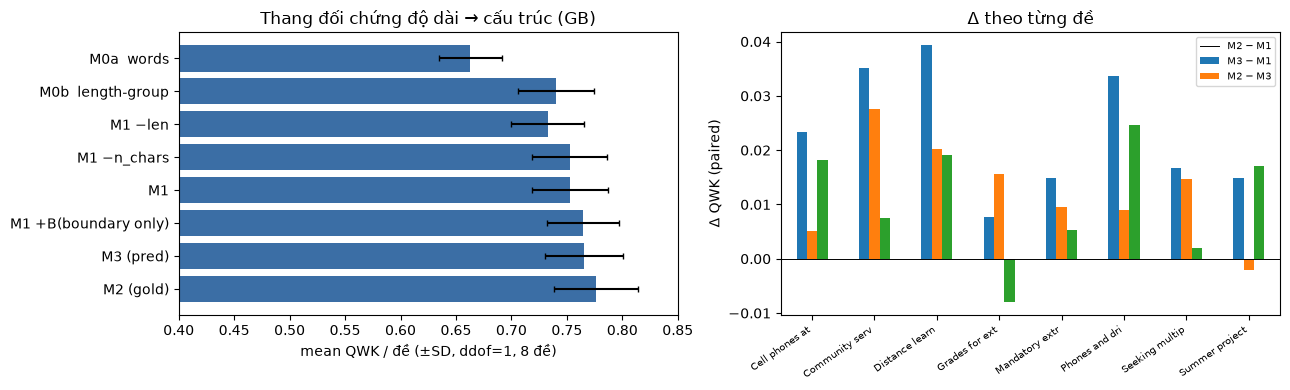

đã lưu: ['nb_delta_gb.csv', 'nb_delta_per_prompt_gb.csv', 'nb_delta_rf.csv', 'nb_duplication_oos.csv', 'nb_main_gb.csv', 'nb_main_rf.csv', 'nb_per_prompt_qwk_gb.csv', 'nb_perm_importance_group.csv', 'nb_predictions.npz']


In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
order = ["M0a  words","M0b  length-group","M1 −len","M1 −n_chars","M1","M1 +B(boundary only)","M3 (pred)","M2 (gold)"]
vals = [tab_gb.loc[n, "mean QWK / đề"] for n in order]; sds = [tab_gb.loc[n, "SD (ddof=1)"] for n in order]
ax[0].barh(order[::-1], vals[::-1], xerr=sds[::-1], color="#3b6ea5", capsize=2); ax[0].set_xlim(0.4, 0.85)
ax[0].set_xlabel("mean QWK / đề (±SD, ddof=1, 8 đề)"); ax[0].set_title("Thang đối chứng độ dài → cấu trúc (GB)")
d = dpp_gb[[c for c in dpp_gb.columns if "M3 − M1" in c or "M2 − M3" in c or "M2 − M1" in c]]
d.plot.bar(ax=ax[1]); ax[1].axhline(0, c="k", lw=.7); ax[1].set_xticklabels([p[:14] for p in prompts], rotation=35, ha="right", fontsize=7)
ax[1].set_ylabel("Δ QWK (paired)"); ax[1].legend([c.split("(")[-1].rstrip(")") for c in d.columns], fontsize=7); ax[1].set_title("Δ theo từng đề")
plt.tight_layout(); plt.savefig(FIGS / "nb_length_control_and_delta.png", dpi=150); plt.show()

# lưu dự đoán để kiểm toán / tái lập
np.savez_compressed(RES / "nb_predictions.npz", essay_id=ess.essay_id_comp.values, prompt=groups, y=y,
                    **{f"{a}__{n}": v for (a, n), v in PRED.items()})
print("đã lưu:", sorted(f.name for f in RES.glob("nb_*")))

## §11. Kết luận được phép / chưa được phép (số lấy từ §5–§8, GB 3 seed, 8 đề, mean QWK/đề)

**Phát hiện chính**

| Câu hỏi | Kết quả | Đọc thế nào |
|---|---|---|
| Độ dài giải thích bao nhiêu của M1−M0a? | M0a 0,663 → M0b (nhóm độ dài) 0,740 → M1 0,753 | M1−M0a = 0,090 thì **0,077 (~86%) đã nằm trong nhóm độ dài**; phần ngôn ngữ còn lại M1−M0b chỉ **+0,013** (8/8 đề dương nhưng nhỏ). Bỏ riêng `n_chars`: Δ ≈ 0,000 → `n_chars` không phải điểm tựa duy nhất, các proxy độ dài thay thế được nhau. |
| Bỏ hết proxy độ dài | M1−len 0,733 (−0,020) | Chỉ ~20 đặc trưng dạng tỉ lệ vẫn đạt 0,733 > M0a 0,663, nhưng đặc trưng tỉ lệ vẫn tương quan độ dài (ttr, max_sent_len…) nên **không** đọc là "ngoài độ dài hoàn toàn". |
| RQ1 gold (M2−M1) | +0,023, 8/8 đề, SD 0,012 (RF: +0,018, 6/8) | Nhất quán về dấu, nhưng nhỏ so với dao động giữa các đề. |
| RQ1 predicted (M3−M1) | +0,012, 7/8 đề, sign-test p=0,07 (RF: +0,002, 5/8) | Yếu; phụ thuộc thuật toán. |
| RQ2 (M2−M3) | +0,011, 7/8 đề, p=0,07 | Mất mát khi dự đoán vai trò (ranh giới vẫn gold) ≈ một nửa lợi ích của M2. |
| **Chỉ ranh giới (không vai trò)** | M1+B−M1 = **+0,012**, 6/8 | **Bằng đúng lợi ích của M3 (+0,012)**: phần lớn cái M3 "thắng" M1 có thể đến từ thông tin ranh giới/số đoạn gold chứ chưa chắc từ vai trò dự đoán. Đây là phát hiện cần nói thẳng với thầy. |
| Cấu trúc khi đã kiểm soát độ dài (M0b) | gold +0,025 (8/8); **pred +0,008 (6/8, p=0,29)** | Gold giúp ngay cả khi có nhóm độ dài; vai trò dự đoán thì chưa chứng minh được. |
| Nhân đôi văn bản, ngoài mẫu | M0a +0,99 điểm; M0b +0,06; M1 +0,05 (0,9% bài tăng ≥1 điểm); M1−len −0,09 | Lối tắt chỉ rõ ở M0a (chỉ số từ). Số +1,82 cũ là từ hồi quy tuyến tính **trong mẫu** – không dùng nữa. |
| Permutation importance (M2) | xáo nhóm độ dài: −0,545 QWK; nhóm cấu trúc gold: −0,088; các nhóm khác ≤ 0,010 | Mô hình *dựa* rất mạnh vào độ dài; cấu trúc là nhóm phụ thuộc lớn thứ hai. Không đọc thành "% điểm do độ dài" (nhóm tương quan nhau). |
| Độ ổn định seed | SD giữa seed ≤ 0,002 | Nhỏ hơn nhiều so với SD giữa các đề (~0,035) → rủi ro nằm ở **số đề (8)**, không ở seed. |

**Ba câu thầy hỏi**
1. *Thêm `n_chars` vào M0 đã tăng mạnh thì còn gọi M1−M0 là lợi ích ngôn ngữ ngoài độ dài không?* → **Không.** ~86% của M1−M0a nằm trong nhóm độ dài; chỉ +0,013 còn lại là phần "ngoài độ dài" (và cũng chỉ ở mức proxy).
2. *M3 biết ranh giới gold thì biết gì mà công cụ nhận bài thô chưa có?* → số đoạn, vị trí, độ dài từng đoạn, đoạn nào là Unannotated. Chỉ riêng chúng (M1+B) đã cho +0,012 ≈ toàn bộ lợi ích của M3.
3. *Vì sao M2 không phải trần?* → M2 chỉ là một scorer (GB + đặc trưng tay làm); scorer/đặc trưng khác có thể xếp hạng khác. M2−M3 = 0,011 là chênh của *một cấu hình*, không phải mức lợi tối đa của transformer.

**Được phép nói:** trên 8 đề PERSUADE Independent (LOPO), cấu trúc **gold** làm tăng nhỏ nhưng nhất quán QWK (+0,02) so với M1, kể cả khi đã có nhóm độ dài mở rộng; phần lớn lợi ích của M1 so với chỉ-số-từ là độ dài.

**Không được kết luận:** "73% điểm chấm do độ dài"; "vai trò dự đoán giúp chấm điểm" (M3−M1 không vượt ranh giới-only, và RF cho ≈0); "cấu trúc giúp ở mọi đề mới" (8 đề, không có đề chưa thấy thật); "đã có công cụ ưu tiên feedback" (Step 2 chưa đủ, chưa đánh giá đầu ra feedback).

**Lưu ý case study (§9):** vài ca "giúp" có điểm thật = 1 là bài nhiễu/lạc đề mà cả M2 lẫn M3 đều kéo điểm xuống – lợi này gần như đến từ *số đoạn ít* (ranh giới) chứ không phải vai trò đúng (ví dụ ca đầu: vai trò dự đoán thiếu Position nhưng điểm vẫn giảm). Nhóm cần tự đọc và diễn giải 6 ca, không để mô hình "kể chuyện" thay mình.

**Bước tiếp theo đề xuất:** (i) thêm đối chứng *M3 không dùng vai trò, chỉ ranh giới* đặt cạnh M3 trong báo cáo; (ii) tách M3 thành "ranh giới dự đoán" nếu còn thời gian (hướng end-to-end); (iii) transformer chỉ thử sau khi pipeline nối vào M3 đã rõ.

---
# PHẦN MỚI · Nâng Step 2 (đánh giá hiệu quả từng đoạn lập luận)

**Vì sao có notebook này.** Step 2 hiện yếu: macro-F1 0,43 (baseline), 0,477 theo đề sau khi chỉnh trọng số lớp; F1 lớp *Ineffective* chỉ 0,07 → 0,126. Mục tiêu của buổi họp là *trên 0,5*. Notebook này thử **3 nâng cấp** trên đúng cách chia cũ (leave-one-prompt-out, 8 đề independent):

| # | Nâng cấp | Block |
|---|---|---|
| 1 | Đo bằng **thước xếp hạng** (PR-AUC, precision/recall/lift trong top 5%) – đúng mục tiêu *ưu tiên cái giáo viên cần xem* | 4, 8 |
| 2 | **Embedding câu** (MiniLM) thay cho TF-IDF | 5, 7 |
| 3 | **Ngữ cảnh văn bản**: độ tương đồng đoạn với câu *Position*, với đoạn liền trước, với trung bình cả bài | 6, 7 |

**Cách chạy:** Run all, chạy từ thư mục `AFP_Project`. Đặt `QUICK = True` ở Block 1 để chạy thử nhanh; `False` = đầy đủ (khoảng 30–60 phút; embedding được lưu cache nên lần sau không tính lại).

**Quy tắc chống rò rỉ:** (i) mô hình bị fit **không có đề giữ lại**; (ii) trọng số lớp chỉ được chỉnh trên dự đoán out-of-fold của 7 đề huấn luyện; (iii) embedding dùng mô hình **đóng băng** (không học nhãn), PCA fit không nhãn.

**Lưu ý trung thực:** kết quả có thể *không* tăng nhiều – nhãn Ineffective chiếm ~1,9% và người chấm chỉ đồng thuận κ = 0,32. Báo cáo cả khi không tăng.

## Step 2 · §1. Cấu hình

In [1]:
# ===== BLOCK S2-1 =====
import os, sys, time, warnings, subprocess
from pathlib import Path
import numpy as np, pandas as pd
from joblib import Parallel, delayed
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import f1_score, average_precision_score, precision_recall_fscore_support
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 50)

# >>> CHỈNH Ở ĐÂY <<<
QUICK = False        # True = chạy thử nhanh (120 bài/đề, 2 tiến trình); False = đầy đủ như báo cáo
N_JOBS = 4           # số đề chạy song song (mỗi tiến trình dùng 4 luồng)
TOP = 0.05           # tỉ lệ đoạn "đáng ngờ nhất" để tính precision/recall/lift
# ----------------------
os.environ.setdefault("OMP_NUM_THREADS", "4")
ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists(): ROOT = ROOT.parent
PROC, RES, FIGS = ROOT / "data" / "processed", ROOT / "results", ROOT / "figs"
for d in (PROC, RES, FIGS): d.mkdir(parents=True, exist_ok=True)
LABELS = ["Adequate", "Effective", "Ineffective"]
try:
    import sentence_transformers
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "sentence-transformers"])
print("ROOT:", ROOT, "| QUICK =", QUICK)

ROOT: d:\Hoa\năm 4\MLA\AFP_Project | QUICK = False


## Step 2 · §2. Dữ liệu: từ file gốc đến bảng đoạn dùng cho Step 2

Mỗi **dòng** = một đoạn lập luận (`discourse_text`) có nhãn vai trò (`discourse_type`) và nhãn hiệu quả (`discourse_effectiveness`: Ineffective / Adequate / Effective). Chỉ giữ **8 đề independent** và bỏ các đoạn *Unannotated* (không có nhãn hiệu quả) cùng 3 đoạn thiếu nhãn.
Từ đoạn và bài chứa nó, ta tính 3 nhóm đặc trưng dày (giải thích ở Block 3).

In [2]:
# ===== BLOCK S2-2 =====
seg = pd.read_pickle(PROC / "segments.pkl")
ess = pd.read_pickle(PROC / "essays.pkl")
ind = ess[ess.task == "Independent"].reset_index(drop=True)          # 7.869 bài / 8 đề; đề source-based bị loại
if (PROC / "features_independent.pkl").exists():
    X1 = pd.read_pickle(PROC / "features_independent.pkl").fillna(0)   # 43 đặc trưng ngôn ngữ cấp bài (M1)
else:
    sys.path.insert(0, str(ROOT / "src")); from features import build_feature_frame
    X1 = build_feature_frame(ind.full_text).fillna(0); X1.to_pickle(PROC / "features_independent.pkl")
X1.insert(0, "essay_id_comp", ind.essay_id_comp.values)

seg = seg[seg.task == "Independent"].merge(ind[["essay_id_comp", "full_text"]], on="essay_id_comp")
seg = seg.sort_values(["essay_id_comp", "discourse_start"]).reset_index(drop=True)   # thứ tự xuất hiện trong bài
seg["role"] = seg.discourse_type
g = seg.groupby("essay_id_comp")
seg["rank"] = g.cumcount(); seg["n_all"] = g.discourse_start.transform("count")
seg["prev_role"] = g.role.shift(1).fillna("START"); seg["next_role"] = g.role.shift(-1).fillna("END")
seg["prev_role2"] = g.role.shift(2).fillna("START")
seg = seg[(seg.role != "Unannotated") & seg.discourse_effectiveness.notna()].copy()
g = seg.groupby("essay_id_comp")
seg["n_in_essay"] = g.discourse_start.transform("count")
seg["rank_rel"] = seg["rank"] / seg.n_all
seg["is_first"] = (seg["rank"] == 0) * 1.0; seg["is_last"] = (seg["rank"] == seg.n_all - 1) * 1.0
seg["rel_pos"] = seg.discourse_start / seg.full_text.str.len()
t = seg.discourse_text; tl = t.str.lower()
seg["log_len"] = np.log1p(seg.seg_len); seg["n_chars"] = t.str.len()
seg["essay_words"] = seg.full_text.str.split().str.len(); seg["len_share"] = seg.seg_len / seg.essay_words
seg["n_sent"] = t.str.count(r"[.!?]+") + 1; seg["avg_wlen"] = seg.n_chars / seg.seg_len.clip(lower=1)
seg["n_comma"] = t.str.count(","); seg["caps"] = t.str.count(r"[A-Z]") / seg.n_chars.clip(lower=1)
seg["has_digit"] = t.str.contains(r"\d") * 1.0
seg["i_cnt"] = tl.str.count(r"\bi\b") / seg.seg_len.clip(lower=1); seg["you_cnt"] = tl.str.count(r"\byou\b") / seg.seg_len.clip(lower=1)
seg["lower_start"] = t.str.strip().str[:1].str.islower() * 1.0
seg["no_end"] = (~t.str.strip().str[-1:].isin([".", "!", "?"])) * 1.0
seg = seg.merge(X1.add_prefix("e_").rename(columns={"e_essay_id_comp": "essay_id_comp"}), on="essay_id_comp")
if QUICK:                                                       # chỉ để thử code nhanh
    keep = seg.groupby("prompt_name").essay_id_comp.transform(lambda s: s.isin(s.unique()[:120]))
    seg = seg[keep]
seg = seg.reset_index(drop=True)
ESS_COLS = [c for c in seg.columns if c.startswith("e_") and c != "essay_words"]
y = seg.discourse_effectiveness.values; gp = seg.prompt_name.values; prompts = sorted(set(gp))
print("đoạn:", len(seg), "| bài:", seg.essay_id_comp.nunique(), "| đề:", len(prompts))
print(pd.Series(y).value_counts().to_frame("n").assign(share=lambda d: (d.n / d.n.sum()).round(3)))
print("\nTỉ lệ Ineffective theo đề:"); print(pd.Series(y == "Ineffective", index=gp).groupby(level=0).mean().round(3).to_string())

đoạn: 77639 | bài: 7869 | đề: 8
                 n  share
Adequate     60156  0.775
Effective    16009  0.206
Ineffective   1474  0.019

Tỉ lệ Ineffective theo đề:
Cell phones at school                    0.033
Community service                        0.051
Distance learning                        0.015
Grades for extracurricular activities    0.024
Mandatory extracurricular activities     0.023
Phones and driving                       0.011
Seeking multiple opinions                0.009
Summer projects                          0.009


## Step 2 · §3. Ba nhóm đặc trưng dày (không dùng văn bản)

* **Vai trò** (one-hot): Lead, Position, Claim, Counterclaim, Rebuttal, Evidence, Concluding – *gold*, giống cách Nhóm 6 dùng `discourse_type`.
* **Độ dài / vị trí / bề mặt đoạn**: số từ, ký tự, câu, vị trí tương đối trong bài, là đoạn đầu hay cuối, dấu phẩy, chữ số, chữ "I"/"you", viết thường đầu đoạn, thiếu dấu kết…
* **Ngữ cảnh bài**: vai trò đoạn trước/sau, tỉ lệ độ dài đoạn so với bài, **43 đặc trưng ngôn ngữ cấp bài của M1** (để mô hình biết bài này nói chung viết tốt hay yếu).

Đây là khối **S3**, mức nền không có tín hiệu văn bản.

In [3]:
# ===== BLOCK S2-3 =====
SEG_STATS = ["rank_rel","is_first","is_last","rel_pos","log_len","n_chars","seg_len","n_sent","avg_wlen","n_comma","caps",
             "has_digit","i_cnt","you_cnt","lower_start","no_end"]
CONTEXT = ["n_in_essay", "len_share", "essay_words"]
roles = pd.get_dummies(seg.role).astype(float)
nb = pd.concat([pd.get_dummies(seg.prev_role, prefix="prev"), pd.get_dummies(seg.next_role, prefix="next"),
                pd.get_dummies(seg.prev_role2, prefix="prev2")], axis=1).astype(float)
S3 = pd.concat([roles, seg[SEG_STATS], seg[CONTEXT], nb, seg[ESS_COLS]], axis=1)
print("S3:", S3.shape)
print("\nTrung bình vài đặc trưng theo nhãn hiệu quả (đoạn tốt có dài hơn không?):")
display(seg.groupby("discourse_effectiveness")[["seg_len","n_sent","rank_rel","len_share"]].mean().round(3))

S3: (77639, 96)

Trung bình vài đặc trưng theo nhãn hiệu quả (đoạn tốt có dài hơn không?):


,seg_len,n_sent,rank_rel,len_share
discourse_effectiveness,,,,
Adequate,36.304,2.642,0.466,0.088
Effective,76.018,4.445,0.513,0.124
Ineffective,36.125,2.524,0.528,0.109


## Step 2 · §4. Hàm đo: macro-F1, **thước xếp hạng**, chỉnh trọng số lớp

* **macro-F1**: trung bình F1 của 3 lớp.
* **PR-AUC (lớp Ineffective)**: xếp các đoạn theo xác suất Ineffective rồi đo chất lượng xếp hạng; *mức đoán bừa bằng tỉ lệ Ineffective (~1,9%)*.
* **precision/recall/lift @ top 5%**: nếu chỉ gắn cờ 5% đoạn đáng ngờ nhất của mỗi đề, bao nhiêu % thật sự là Ineffective, bắt được bao nhiêu % tổng số, và gấp mấy lần đoán bừa (`lift = precision / tỉ lệ nền`).
* **Trọng số lớp** `w = (1, a, b)` nhân vào xác suất trước `argmax`; `a, b` chọn trên **dự đoán out-of-fold của 7 đề huấn luyện**, không nhìn đề giữ lại.

In [4]:
# ===== BLOCK S2-4 =====
def hgb(seed=0):
    return HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_depth=6, l2_regularization=1.0, random_state=seed)

def tune_weights(P, yy):
    best, bw = -1, (1.0, 1.0, 1.0)
    for a in np.linspace(0.5, 5, 10):
        for b in np.linspace(0.5, 40, 40):
            s = f1_score(yy, np.array(LABELS)[(P * np.array([1, a, b])).argmax(1)], average="macro", labels=LABELS)
            if s > best: best, bw = s, (1.0, a, b)
    return np.array(bw)

def rank_metrics(p_ineff, yy):
    pos = (yy == "Ineffective"); k = max(int(round(TOP * len(yy))), 1); top = np.argsort(-p_ineff)[:k]
    prec = pos[top].mean()
    return {"PR_AUC": average_precision_score(pos, p_ineff), "prec_top5": prec,
            "recall_top5": pos[top].sum() / max(pos.sum(), 1), "lift_top5": prec / max(pos.mean(), 1e-9), "base_rate": pos.mean()}

def label_metrics(yy, pred):
    per = [f1_score(yy[gp == p], pred[gp == p], average="macro", labels=LABELS, zero_division=0) for p in prompts]
    pr, rc, f1, _ = precision_recall_fscore_support(yy, pred, labels=LABELS, zero_division=0)
    return {"macroF1_pooled": f1_score(yy, pred, average="macro", labels=LABELS, zero_division=0),
            "macroF1_mean_prompts": np.mean(per), "SD_prompts": np.std(per, ddof=1),
            "F1_Ineffective": f1[2], "P_Ineffective": pr[2], "R_Ineffective": rc[2]}
print("đã định nghĩa hàm đo")

đã định nghĩa hàm đo


## Step 2 · §5. Nâng cấp 2 – embedding câu (MiniLM, mô hình đóng băng)

`all-MiniLM-L6-v2` biến mỗi đoạn thành vector 384 chiều nắm *nghĩa* (TF-IDF chỉ đếm từ). Mô hình **không được huấn luyện lại bằng nhãn của ta**, nên không có rò rỉ nhãn. Lần đầu tính mất vài phút đến vài chục phút trên CPU; kết quả lưu vào `data/processed/seg_emb*.npz`.

In [5]:
# ===== BLOCK S2-5 =====
cache = PROC / ("seg_emb_quick.npz" if QUICK else "seg_emb.npz")
E = None
if cache.exists():
    z = np.load(cache, allow_pickle=True)
    if len(z["ids"]) == len(seg) and (z["ids"] == seg.discourse_id.values).all(): E = z["E"]; print("nạp cache", cache.name)
if E is None:
    from sentence_transformers import SentenceTransformer
    t0 = time.time()
    model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device="cpu")
    E = model.encode(seg.discourse_text.tolist(), batch_size=128, show_progress_bar=True, normalize_embeddings=True).astype("float32")
    np.savez_compressed(cache, ids=seg.discourse_id.values, E=E); print(f"embedding {len(seg)} đoạn: {time.time()-t0:.0f}s")
print("E:", E.shape)

Batches: 100%|██████████| 607/607 [12:07<00:00,  1.20s/it]


embedding 77639 đoạn: 734s
E: (77639, 384)


## Step 2 · §6. Nâng cấp 3 – ngữ cảnh văn bản + PCA

Ba độ tương đồng cosine (vector đã chuẩn hoá):

* `sim_position`: đoạn này liên quan thế nào tới **câu Position** (luận điểm chính) của bài.
* `sim_prev`: liên quan thế nào tới **đoạn liền trước** (có mạch lạc không).
* `sim_essay_mean`: nằm gần hay xa **trọng tâm** của cả bài (lạc đề?).

Embedding 384 chiều được nén còn **64 chiều bằng PCA** (không nhãn) cho gọn.

In [6]:
# ===== BLOCK S2-6 =====
eid = seg.essay_id_comp.values; n = len(seg)
prev = np.zeros(n); same = np.r_[False, eid[1:] == eid[:-1]]
prev[same] = (E[1:] * E[:-1]).sum(1)[same[1:]]
cent = pd.DataFrame(E).groupby(eid).transform("mean").values
cent /= np.linalg.norm(cent, axis=1, keepdims=True) + 1e-9
is_pos = (seg.role == "Position").values
pos_idx = pd.Series(np.arange(n))[is_pos].groupby(eid[is_pos]).first()
pi = pd.Series(eid).map(pos_idx); has_pos = pi.notna().values
to_pos = np.zeros(n); to_pos[has_pos] = (E[has_pos] * E[pi[has_pos].astype(int).values]).sum(1)
sims = pd.DataFrame({"sim_prev": prev, "sim_essay_mean": (E * cent).sum(1), "sim_position": to_pos, "has_position": has_pos * 1.0})
Z = pd.DataFrame(PCA(64, random_state=0).fit_transform(E), columns=[f"emb{i}" for i in range(64)])
print("Độ tương đồng trung bình theo nhãn hiệu quả (đoạn Effective có bám luận điểm hơn không?):")
display(sims.assign(eff=y)[sims.has_position.values == 1].groupby("eff")[["sim_position","sim_prev","sim_essay_mean"]].mean().round(3))
BLOCKS = {"S3 no text signal": S3, "S5 +embedding": pd.concat([S3, Z], axis=1),
          "S6 +embedding +context sims": pd.concat([S3, Z, sims], axis=1)}
print({k: v.shape for k, v in BLOCKS.items()})

Độ tương đồng trung bình theo nhãn hiệu quả (đoạn Effective có bám luận điểm hơn không?):


,sim_position,sim_prev,sim_essay_mean
eff,,,
Adequate,0.524,0.412,0.702
Effective,0.534,0.448,0.728
Ineffective,0.460,0.371,0.669


{'S3 no text signal': (77639, 96), 'S5 +embedding': (77639, 160), 'S6 +embedding +context sims': (77639, 164)}


## Step 2 · §7. Chạy leave-one-prompt-out

Với mỗi đề giữ lại `p`: fit trên 7 đề còn lại để lấy xác suất cho `p`; đồng thời fit 7 lần *trong* 7 đề huấn luyện (bỏ lần lượt từng đề) để lấy dự đoán out-of-fold và chọn trọng số lớp. Có 3 khối đặc trưng × 8 đề × 8 lần fit.

In [7]:
# ===== BLOCK S2-7 =====
def one_fold(p):
    t0 = time.time(); te = gp == p; tr = ~te; trp = sorted(set(gp[tr])); out = {}
    for name, X in BLOCKS.items():
        P_te = hgb().fit(X[tr], y[tr]).predict_proba(X[te])
        Xtr, ytr, gtr = X[tr], y[tr], gp[tr]; P_in = np.zeros((int(tr.sum()), 3))
        for q in trp:
            iq = gtr == q; P_in[iq] = hgb().fit(Xtr[~iq], ytr[~iq]).predict_proba(Xtr[iq])
        out[name] = (P_te, tune_weights(P_in, ytr))
    print(f"{p:40s} xong sau {time.time()-t0:.0f}s", flush=True)
    return p, out

t0 = time.time()
RESULT = dict(Parallel(n_jobs=2 if QUICK else N_JOBS)(delayed(one_fold)(p) for p in prompts))
print(f"tổng {(time.time()-t0)/60:.1f} phút")

tổng 21.7 phút


## Step 2 · §8. Bảng kết quả

Đọc: (1) so `macroF1_*` và `F1_Ineffective` giữa các khối; (2) **so `PR_AUC` và `prec_top5` với `base_rate`** – nếu chỉ hơn mức nền chút ít thì cờ chưa hữu ích; (3) `lift_top5` = gấp mấy lần đoán bừa. Các cột xếp hạng là trung bình 8 đề.

In [8]:
# ===== BLOCK S2-8 =====
rows = []
for name in BLOCKS:
    for tuned in (False, True):
        pred = np.empty(len(y), dtype=object); pi_ = np.zeros(len(y))
        for p in prompts:
            P, w = RESULT[p][name]; m = gp == p
            pred[m] = np.array(LABELS)[(P * (w if tuned else 1)).argmax(1)]; pi_[m] = P[:, 2]
        rk = [rank_metrics(pi_[gp == p], y[gp == p]) for p in prompts]
        rows.append({"model": name, "weights": "tuned" if tuned else "argmax", **label_metrics(y, pred),
                     **{k: np.mean([r[k] for r in rk]) for k in rk[0]}})
TAB = pd.DataFrame(rows).round(3)
TAB.to_csv(RES / ("step2_embed_summary_quick.csv" if QUICK else "step2_embed_summary.csv"), index=False)
display(TAB[["model","weights","macroF1_pooled","macroF1_mean_prompts","F1_Ineffective","PR_AUC","prec_top5","recall_top5","lift_top5","base_rate"]])
print("Mốc tham chiếu (báo cáo Tuần 9, baseline LR TF-IDF): macroF1 gộp 0,433 | F1 Ineffective 0,07")
print("Mốc 06_step2_improved (S4, chỉnh trọng số): macroF1 gộp 0,510 | theo đề 0,477 | F1 Ineffective 0,126")

,model,weights,macroF1_pooled,macroF1_mean_prompts,F1_Ineffective,PR_AUC,prec_top5,recall_top5,lift_top5,base_rate
0,S3 no text signal,argmax,0.464,0.430,0.004,0.072,0.083,0.218,4.363,0.022
1,S3 no text signal,tuned,0.509,0.477,0.120,0.072,0.083,0.218,4.363,0.022
2,S5 +embedding,argmax,0.469,0.427,0.012,0.078,0.090,0.225,4.497,0.022
3,S5 +embedding,tuned,0.510,0.472,0.121,0.078,0.090,0.225,4.497,0.022
4,S6 +embedding +context sims,argmax,0.466,0.425,0.007,0.074,0.093,0.234,4.678,0.022
5,S6 +embedding +context sims,tuned,0.513,0.473,0.123,0.074,0.093,0.234,4.678,0.022


Mốc tham chiếu (báo cáo Tuần 9, baseline LR TF-IDF): macroF1 gộp 0,433 | F1 Ineffective 0,07
Mốc 06_step2_improved (S4, chỉnh trọng số): macroF1 gộp 0,510 | theo đề 0,477 | F1 Ineffective 0,126


### Step 2 · §8b. Theo từng đề (khối cuối, trọng số đã chỉnh)

,n,n_Ineff,macroF1,PR_AUC,prec_top5,recall_top5,lift_top5,base_rate
đề,,,,,,,,
Cell phones at school,7074,233,0.475,0.122,0.155,0.236,4.717,0.033
Community service,6461,331,0.388,0.123,0.167,0.163,3.263,0.051
Distance learning,18526,277,0.526,0.071,0.079,0.264,5.272,0.015
Grades for extracurricular activities,6122,146,0.426,0.067,0.092,0.192,3.837,0.024
Mandatory extracurricular activities,8455,198,0.513,0.085,0.097,0.207,4.139,0.023
Phones and driving,6584,70,0.486,0.025,0.036,0.171,3.431,0.011
Seeking multiple opinions,14562,131,0.477,0.036,0.049,0.275,5.497,0.009
Summer projects,9855,88,0.497,0.065,0.065,0.364,7.269,0.009


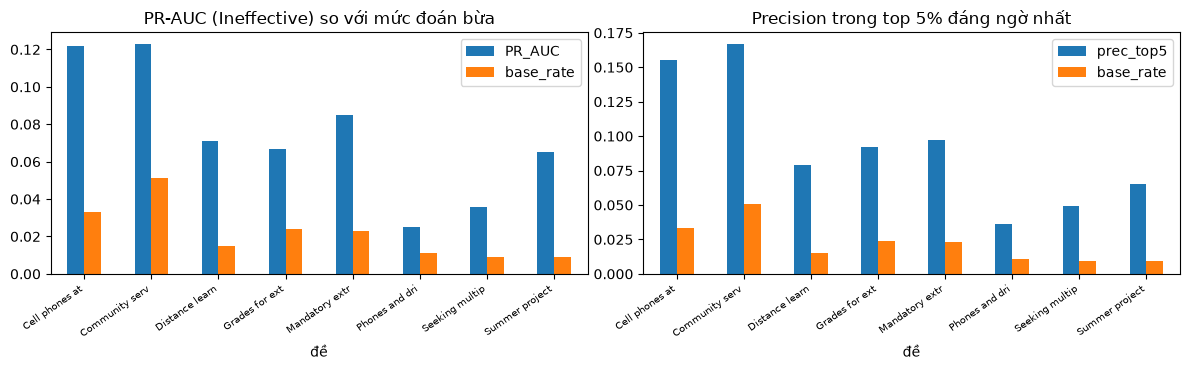

In [9]:
# ===== BLOCK S2-9 =====
last = list(BLOCKS)[-1]; rows = []
for p in prompts:
    P, w = RESULT[p][last]; m = gp == p; pr = np.array(LABELS)[(P * w).argmax(1)]
    rk = rank_metrics(P[:, 2], y[m])
    rows.append({"đề": p, "n": int(m.sum()), "n_Ineff": int((y[m] == "Ineffective").sum()),
                 "macroF1": f1_score(y[m], pr, average="macro", labels=LABELS, zero_division=0), **rk})
PP = pd.DataFrame(rows).set_index("đề").round(3); display(PP)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
PP[["PR_AUC", "base_rate"]].plot.bar(ax=ax[0]); ax[0].set_title("PR-AUC (Ineffective) so với mức đoán bừa"); ax[0].set_xticklabels([s[:14] for s in PP.index], rotation=35, ha="right", fontsize=7)
PP[["prec_top5", "base_rate"]].plot.bar(ax=ax[1]); ax[1].set_title("Precision trong top 5% đáng ngờ nhất"); ax[1].set_xticklabels([s[:14] for s in PP.index], rotation=35, ha="right", fontsize=7)
plt.tight_layout(); plt.savefig(FIGS / "step2_embed_ranking.png", dpi=150); plt.show()

## Step 2 · §9. Cách diễn giải (điền bằng lời của nhóm sau khi chạy)

* **Nếu S5/S6 hơn S3 rõ** (macro-F1 và PR-AUC cùng tăng, ở nhiều đề): embedding và ngữ cảnh nắm được tín hiệu mà đặc trưng tay bỏ sót.
* **Nếu gần bằng nhau**: tín hiệu văn bản bị chặn bởi nhãn nhiễu (κ = 0,32) và tỉ lệ Ineffective rất thấp; Step 2 vẫn chưa dùng làm cờ cho giáo viên.
* **Nếu `prec_top5` chỉ vài % và `lift` gần 1–3**: gắn cờ top 5% vẫn phần lớn là báo nhầm, ghi nhận là *giới hạn*, không gọi là công cụ ưu tiên feedback.
* Nhắc: các dòng chỉnh trọng số có macro-F1 cao hơn chủ yếu do **đổi ngưỡng quyết định**, không phải do mô hình phân biệt tốt hơn; PR-AUC (không phụ thuộc ngưỡng) mới phản ánh khả năng phân biệt.